<a href="https://colab.research.google.com/github/rxphaelbihag/DS171-Intro-to-Supervised-Machine-Learning/blob/main/Laboratory_Exercise_7_Feed_Forward_Neural_Network_on_Digit_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratory Exercise 7: Feed Forward Neural Network on Digit Dataset
Student No.: 2024-05203

Name: Raphael Khandie B. Bihag

Section: DS171 (N-1L)

In [ ]:
# Importing the libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Instructions:

*   Read and follow the given instructions.
*   A step-by-step process is given in each cell. Implement the required tasks.
*   For the synthesis questions, write your answers in the next cell. Your answers should be only 2-3 sentences.



Fetch and load the dataset

In [ ]:
from sklearn.datasets import load_digits
digits = load_digits()
X = digits.data
y = digits.target

# Print to show there are 1797 images (8 by 8 images for a dimensionality of 64)
print("Image Data Shape" , X.shape)

# Print to show there are 1797 labels (integers from 0–9)
print("Label Data Shape", y.shape)

# Print the classes
print("Classes", np.unique(y))

Image Data Shape (1797, 64)
Label Data Shape (1797,)
Classes [0 1 2 3 4 5 6 7 8 9]


Visualizing Sample Handwritten Digits

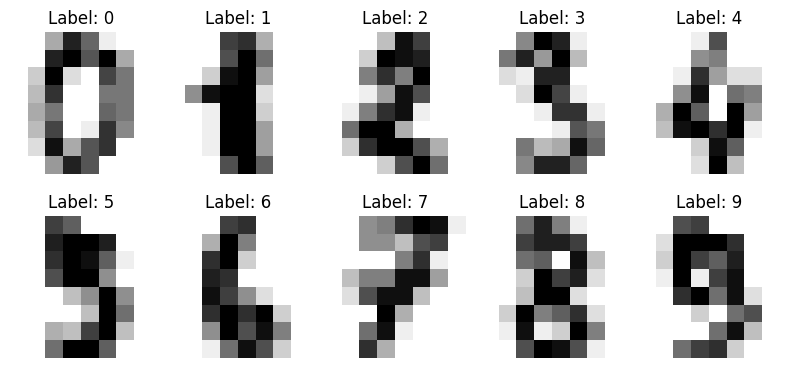

In [ ]:
# Plotting the images from the dataset
fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap='binary')
    ax.set_title(f"Label: {digits.target[i]}")
    ax.axis('off')
plt.tight_layout()
plt.show()

Splitting the Dataset into Training Set and Test Set

In [ ]:
from sklearn.model_selection import train_test_split

# Split data: 75% training, 25% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

Feature Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

# Scale features to zero mean and unit variance
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

Building and Fitting the Feedforward Neural Network (MLPClassifier)

In [ ]:
# Building and fitting the Multi-Layer Perceptron for 10-class image classification
from sklearn.neural_network import MLPClassifier

# Architecture: Input (64 features) -> Hidden Layer 1 (64 neurons, ReLU) -> Hidden Layer 2 (32 neurons, ReLU) -> Output Layer (10 classes, Softmax)
ann_classifier = MLPClassifier(hidden_layer_sizes=(64, 32),
                               activation='relu',
                               solver='adam',
                               max_iter=500,
                               random_state=0)

ann_classifier.fit(X_train, y_train)

MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=0)

Predicting Test Set Results and Output Probabilities (Softmax Layer)

In [ ]:
# Predicting Test set results
y_pred = ann_classifier.predict(X_test)

# Predict probability distribution across all 10 digit classes for first 5 test samples
probs_y = ann_classifier.predict_proba(X_test[:5])
probs_df = pd.DataFrame(probs_y, columns=[f"Digit {i}" for i in range(10)])
probs_df['Predicted'] = y_pred[:5]
probs_df['True Label'] = y_test[:5]

print("Sample Class Prediction Probabilities:")
probs_df.round(3)

Sample Class Prediction Probabilities:


,Digit 0,Digit 1,Digit 2,Digit 3,Digit 4,Digit 5,Digit 6,Digit 7,Digit 8,Digit 9,Predicted,True Label
0,0.002,0.0,0.964,0.029,0.000,0.0,0.0,0.000,0.0,0.004,2,2
1,1.000,0.0,0.000,0.000,0.000,0.0,0.0,0.000,0.0,0.000,0,0
2,0.000,0.0,0.000,0.000,1.000,0.0,0.0,0.000,0.0,0.000,4,4
3,0.000,0.0,0.000,0.000,0.000,0.0,0.0,0.001,0.0,0.998,9,9
4,0.001,0.0,0.000,0.000,0.997,0.0,0.0,0.002,0.0,0.000,4,4


## **Your** **Tasks**


1.   Plot the training loss curve.
2.   Create and plot the $10 \times 10$ Confusion Matrix.
3.   Calculate the overall test accuracy.
4.   Calculate the evaluation metrics (precision, recall, and F1-score) across all digits (0-9).



In [ ]:
from sklearn import metrics # metrics class from sklearn
import matplotlib.pyplot as plt
import seaborn as sns

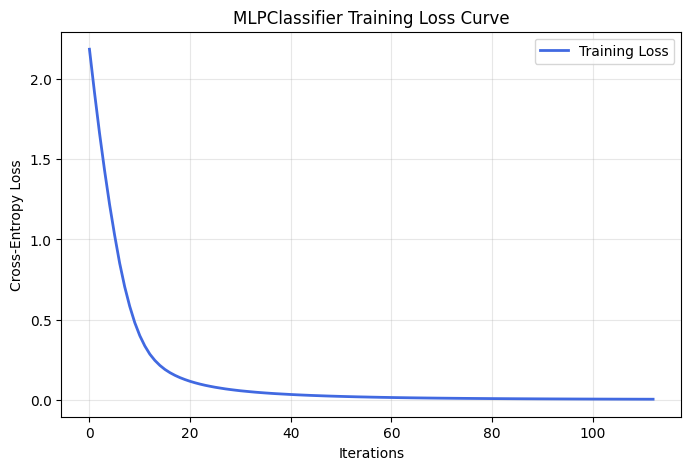

In [ ]:
# Training Loss Curve
plt.figure(figsize=(8, 5))
plt.plot(ann_classifier.loss_curve_, label="Training Loss", color="royalblue", linewidth=2)
plt.title("MLPClassifier Training Loss Curve")
plt.xlabel("Iterations")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

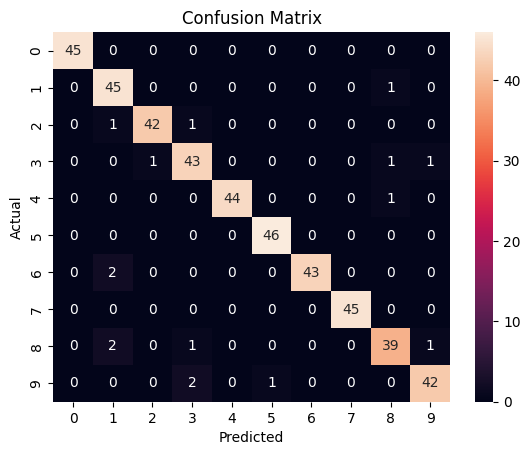

In [ ]:
# Confusion Matrix
conf_matrix = metrics.confusion_matrix(y_test, y_pred)

# plot confusion matrix using seaborn's heatmap
classes = ann_classifier.classes_
sns.heatmap(conf_matrix, annot=True, xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# Overall test accuracy
accuracy = metrics.accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy*100:.2f}%")

Accuracy: 96.44%


In [ ]:
# Classification Report
class_report = metrics.classification_report(y_test, y_pred)
print("Classification Report:\n", class_report)

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        45
           1       0.90      0.98      0.94        46
           2       0.98      0.95      0.97        44
           3       0.91      0.93      0.92        46
           4       1.00      0.98      0.99        45
           5       0.98      1.00      0.99        46
           6       1.00      0.96      0.98        45
           7       1.00      1.00      1.00        45
           8       0.93      0.91      0.92        43
           9       0.95      0.93      0.94        45

    accuracy                           0.96       450
   macro avg       0.97      0.96      0.96       450
weighted avg       0.97      0.96      0.96       450



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

test_sizes = [0.10, 0.15, 0.25]

for _ in test_sizes:
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=_, random_state=0, stratify=y)

    # Scale features to zero mean and unit variance
    sc = StandardScaler()
    X_train = sc.fit_transform(X_train)
    X_test = sc.transform(X_test)

    # Building and fitting the Multi-Layer Perceptron for 10-class image classification


    # Architecture: Input (64 features) -> Hidden Layer 1 (64 neurons, ReLU) -> Hidden Layer 2 (32 neurons, ReLU) -> Output Layer (10 classes, Softmax)
    ann_classifier = MLPClassifier(hidden_layer_sizes=(64, 32),
                                activation='relu',
                                solver='adam',
                                max_iter=500,
                                random_state=0)

    ann_classifier.fit(X_train, y_train)

    # Predicting Test set results
    y_pred = ann_classifier.predict(X_test)

    # Overall test accuracy
    accuracy = metrics.accuracy_score(y_test, y_pred)
    print(f"Accuracy at {_*100:.2f}% Test Size: {accuracy*100:.2f}%")

Accuracy at 10.00% Test Size: 96.11%
Accuracy at 15.00% Test Size: 97.04%
Accuracy at 25.00% Test Size: 96.44%


### **Analytical Questions**


*   Q1: How does increasing the width and depth of hidden layers (e.g., 64 and 32 neurons) allow the Multi-Layer Perceptron to construct high-dimensional feature representations for complex pattern recognition? How does the Digit dataset differ from tabular datasets?
*   Q2: Based on your $10 \times 10$ confusion matrix, which pair of handwritten digits suffered the most misclassification overlap, and how do visual pixel similarities between these digits explain the gradient descent challenge for non-convolutional dense layers?
*   Q3: Modify the test data split to 10% and 15%. What did you obeserve to the accuracy of the model?



**Q1:**
> Increasing the width of the hidden layers allows the model to capture the complexities of the data and recognize the abstract pattern while increasing the depth of the hidden layers allows the model to improve accuracy by building on what the previous layer has missed and work on that. It is important to appropriately choose the number of layers and the number of neurons for each layer to prevent underfitting or overfitting. Although the the digit dataset is transformed into a tabular for better model computation, it diffes from tabular datasets mainly because it requires recognition of spatial relationships from the model.

**Q2:**
> From the confusion matrix, the handwritten digit pair of 3 and 9 appears so have suffered the most misclassification overlap. This is primarily because of how similar the visual representation of these two numbers such that, with a very low-resolution image data, there is a higher probability of the two having almost equal prediction confidence.

**Q3:**
> Running the MLP on three different test sizes appear to have resulted in varying model accuracy. The 10% test data split has an accuracy of 96.11%, while the 15% test data split has 97.04%. Comparing with the standard of 25% split, this shows that there is a sweet spot between the amount of training data and testing data.

##**Submission**:
Save all your code and analysis answers in a single Jupyter notebook. Make sure that your notebook has the student number, full name, and section commented in the first cell. Export the notebook with complete executed outputs and save it following the filename format “surname_section_labexe7.ipynb”.
- Submit your notebook to the LMS submission bin on or before the specified deadline.
- Late submission will be subject to a point deduction (10% per day, up to a 3-day maximum delay).
- Submissions that do not comply with the stated requirements and guidelines will be graded 0. Refer to the course syllabus for details on the source code evaluation rubric.